<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/5_gravity_cosmo_strings/string_theory/string_ch03_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*String Theory* — `string_ch03_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# String Theory Ch 3 — Figure Notebook
**Open Strings and D-Branes**

In [1]:
FIG_DIR = 'figures/ch03'

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os

BG='#1e1e2e';FG='#cdd6f4';EDGE='#45475a'
SKYB='#89c4f4';YELL='#f9c74f';GREEN='#90ee90'
RED='#e07070';PURP='#c792ea';ORAN='#e8a838';TEAL='#2ec4b6'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,
    'text.color':FG,'axes.labelcolor':FG,
    'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.25,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':SKYB,'legend.framealpha':0.3,
    'legend.edgecolor':EDGE,'lines.linewidth':2.2,
    'axes.linewidth':1.2,'figure.dpi':110,
})
os.makedirs(FIG_DIR, exist_ok=True)

def save(name, fig):
    fig.savefig(f'{FIG_DIR}/{name}', dpi=150, bbox_inches='tight', facecolor=BG)
    plt.show(); print(f'Saved: {FIG_DIR}/{name}')

print('Setup complete.')


Setup complete.


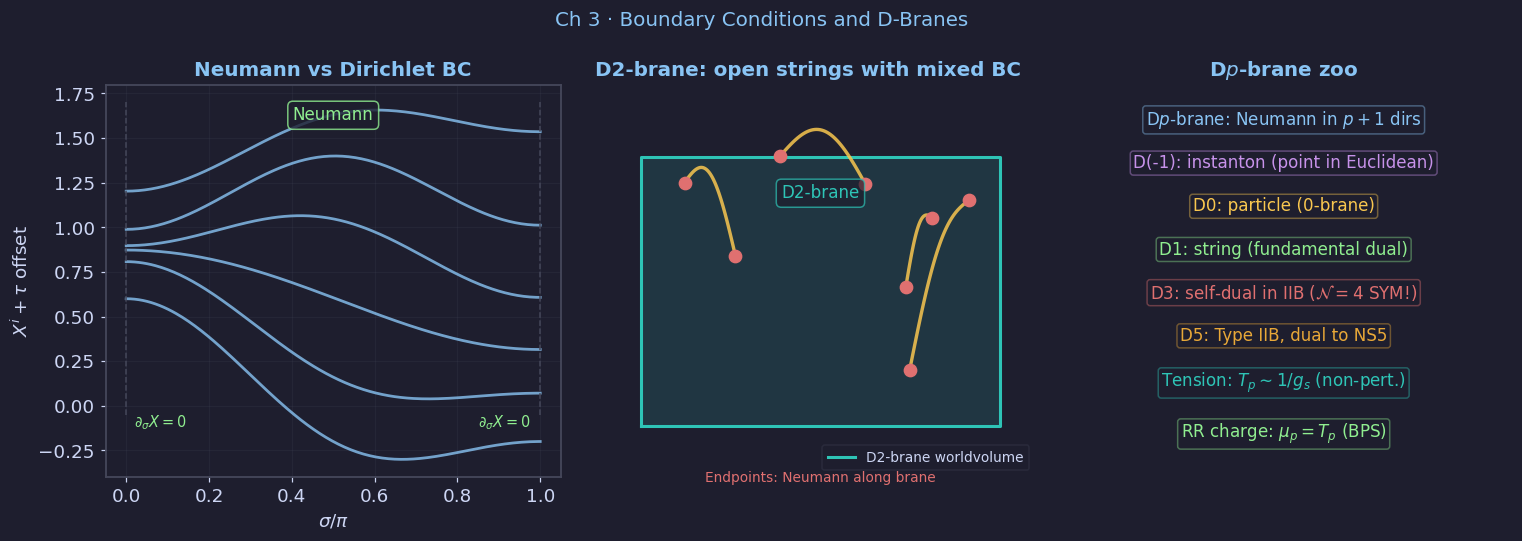

Saved: figures/ch03/fig01_dbranes_bc.png


In [2]:

# ── fig01: Boundary conditions and D-brane picture ───────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle('Ch 3 · Boundary Conditions and D-Branes', color=SKYB, fontsize=13)

# Left: Neumann vs Dirichlet BC
ax = axes[0]; ax.set_facecolor(BG)
ax.set_title('Neumann vs Dirichlet BC', color=SKYB)
sigma_o = np.linspace(0, np.pi, 200)
tau_plot = np.linspace(0, 2, 6)

for i, tau in enumerate(tau_plot):
    amp = 0.4
    # Neumann: derivative zero at endpoints -> cosine modes
    y_N = amp * np.cos(sigma_o) * np.cos(tau) + amp*0.5*np.cos(2*sigma_o)*np.cos(2*tau)
    ax.plot(sigma_o/np.pi, y_N + i*0.3, color=SKYB, lw=1.8, alpha=0.8)

# Mark Neumann endpoints (free)
ax.plot([0, 0], [-0.05, 1.7], color=EDGE, lw=1, ls='--')
ax.plot([1, 1], [-0.05, 1.7], color=EDGE, lw=1, ls='--')
ax.text(0.02, -0.12, r'$\partial_\sigma X=0$', fontsize=9.5, color=GREEN)
ax.text(0.85, -0.12, r'$\partial_\sigma X=0$', fontsize=9.5, color=GREEN)
ax.text(0.5, 1.60, 'Neumann', ha='center', fontsize=11, color=GREEN,
        bbox=dict(boxstyle='round', fc=BG, ec=GREEN, alpha=0.8))
ax.set_xlabel(r'$\sigma/\pi$'); ax.set_ylabel(r'$X^i + \tau$ offset')
ax.grid(True, alpha=0.2)

# Middle: D-brane schematic
ax2 = axes[1]; ax2.set_facecolor(BG)
ax2.set_title('D2-brane: open strings with mixed BC', color=SKYB)
ax2.set_xlim(-0.3, 3.5); ax2.set_ylim(-0.3, 3.5); ax2.axis('off')

# Draw D2-brane (a plane)
brane_x = [0.2, 3.2, 3.2, 0.2]
brane_y = [0.2, 0.2, 2.8, 2.8]
ax2.fill(brane_x, brane_y, color=TEAL, alpha=0.15)
ax2.plot(brane_x + [brane_x[0]], brane_y + [brane_y[0]],
         color=TEAL, lw=2, label='D2-brane worldvolume')
ax2.text(1.7, 2.4, 'D2-brane', color=TEAL, fontsize=11, ha='center',
         bbox=dict(boxstyle='round', fc=BG, ec=TEAL, alpha=0.7))

# Draw open strings ending on brane
rng = np.random.default_rng(42)
for _ in range(4):
    x0, y0 = rng.uniform(0.4, 3.0, 2)
    x1, y1 = rng.uniform(0.4, 3.0, 2)
    # String dangles above the brane
    xs = np.linspace(0, 1, 50)
    xp = x0 + (x1-x0)*xs
    yp = y0 + (y1-y0)*xs + 0.8*np.sin(np.pi*xs) * rng.uniform(0.3, 0.7)
    ax2.plot(xp, yp, color=YELL, lw=2.2, alpha=0.85)
    ax2.plot([xp[0], xp[-1]], [yp[0], yp[-1]], 'o', color=RED, ms=8)

ax2.text(1.7, -0.34, 'Endpoints: Neumann along brane', fontsize=9,
         color=RED, ha='center')
ax2.legend(fontsize=9, loc='lower right')

# Right: D-brane hierarchy
ax3 = axes[2]; ax3.set_facecolor(BG); ax3.axis('off')
ax3.set_title('D$p$-brane zoo', color=SKYB)
items = [
    (0.5, 0.91, r'D$p$-brane: Neumann in $p+1$ dirs', SKYB),
    (0.5, 0.80, r'D(-1): instanton (point in Euclidean)',PURP),
    (0.5, 0.69, r'D0: particle (0-brane)',               YELL),
    (0.5, 0.58, r'D1: string (fundamental dual)',        GREEN),
    (0.5, 0.47, r'D3: self-dual in IIB ($\mathcal{N}=4$ SYM!)', RED),
    (0.5, 0.36, r'D5: Type IIB, dual to NS5',            ORAN),
    (0.5, 0.24, r'Tension: $T_p\sim 1/g_s$ (non-pert.)', TEAL),
    (0.5, 0.11, r'RR charge: $\mu_p=T_p$ (BPS)',         GREEN),
]
for x_,y_,txt,col in items:
    ax3.text(x_,y_,txt,ha='center',va='center',fontsize=11,color=col,
             transform=ax3.transAxes,
             bbox=dict(boxstyle='round,pad=0.18',fc=BG,ec=col,alpha=0.4))

plt.tight_layout()
save('fig01_dbranes_bc.png', fig)


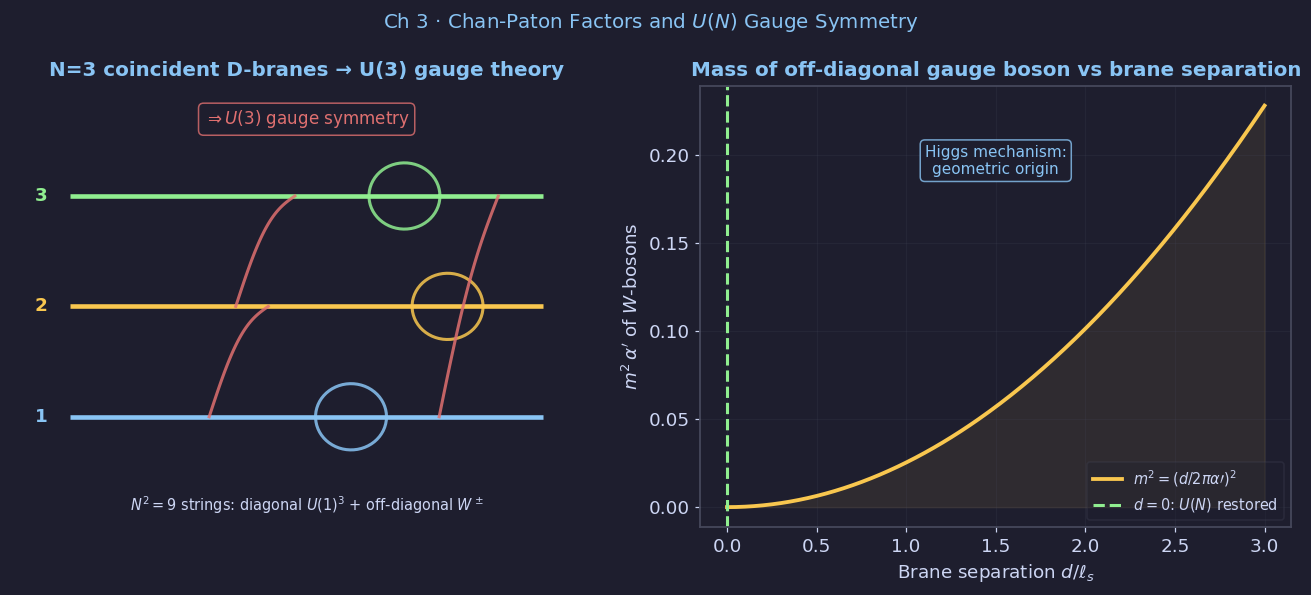

Saved: figures/ch03/fig02_chan_paton.png


In [3]:

# ── fig02: Chan-Paton factors and gauge symmetry ──────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
fig.suptitle(r'Ch 3 · Chan-Paton Factors and $U(N)$ Gauge Symmetry',
             color=SKYB, fontsize=13)

# Left: N coincident branes
ax = axes[0]; ax.set_facecolor(BG)
ax.set_title('N=3 coincident D-branes → U(3) gauge theory', color=SKYB)
ax.set_xlim(-0.5, 4.5); ax.set_ylim(-0.5, 3.5); ax.axis('off')

brane_ys = [0.5, 1.5, 2.5]
colors_b = [SKYB, YELL, GREEN]
for i, (y, col) in enumerate(zip(brane_ys, colors_b)):
    ax.hlines(y, 0, 4, colors=col, lw=3, label=f'Brane {i+1}')
    ax.text(-0.3, y, str(i+1), color=col, fontsize=12, va='center', fontweight='bold')

# Strings between branes
pairs = [(0,0,'diagonal'),(1,1,'diagonal'),(2,2,'diagonal'),
         (0,1,'off-diag'),(1,2,'off-diag'),(0,2,'off-diag')]
rng = np.random.default_rng(7)
for (i,j,kind) in pairs:
    x_c = rng.uniform(0.5, 3.5)
    xs = np.linspace(0, 1, 60)
    if i == j:
        # small loop on brane
        xp = x_c + 0.3*np.cos(2*np.pi*xs)
        yp = brane_ys[i] + 0.3*np.sin(2*np.pi*xs)
        col = colors_b[i]
    else:
        xp = np.linspace(x_c, x_c+0.5, 60)
        yp = (brane_ys[i] + (brane_ys[j]-brane_ys[i])*xs +
              0.2*np.sin(np.pi*xs))
        col = RED
    ax.plot(xp, yp, color=col, lw=2, alpha=0.85)

ax.text(2, -0.35, r'$N^2=9$ strings: diagonal $U(1)^3$ + off-diagonal $W^\pm$',
        ha='center', fontsize=9.5, color=FG)
ax.text(2, 3.15, r'$\Rightarrow U(3)$ gauge symmetry',
        ha='center', fontsize=11, color=RED,
        bbox=dict(boxstyle='round', fc=BG, ec=RED, alpha=0.8))

# Right: mass vs separation
ax2 = axes[1]; ax2.set_facecolor(BG)
ax2.set_title(r'Mass of off-diagonal gauge boson vs brane separation', color=SKYB)
d = np.linspace(0, 3, 300)   # separation in units of ell_s
m2 = d**2 / (2*np.pi)**2     # m^2 = (d/2pi alpha')^2 schematic

ax2.plot(d, m2, color=YELL, lw=2.5, label=r'$m^2 = (d/2\pi\alpha\prime)^2$')
ax2.axvline(0, color=GREEN, lw=2, ls='--', label=r'$d=0$: $U(N)$ restored')
ax2.fill_between(d, 0, m2, color=YELL, alpha=0.08)
ax2.set_xlabel(r'Brane separation $d/\ell_s$')
ax2.set_ylabel(r"$m^2\,\alpha'$ of $W$-bosons")
ax2.legend(fontsize=9.5, loc="lower right"); ax2.grid(True, alpha=0.2)
ax2.text(0.5, 0.8, 'Higgs mechanism:\ngeometric origin',
         transform=ax2.transAxes, ha='center', fontsize=10, color=SKYB,
         bbox=dict(boxstyle='round', fc=BG, ec=SKYB, alpha=0.8))

plt.tight_layout()
save('fig02_chan_paton.png', fig)


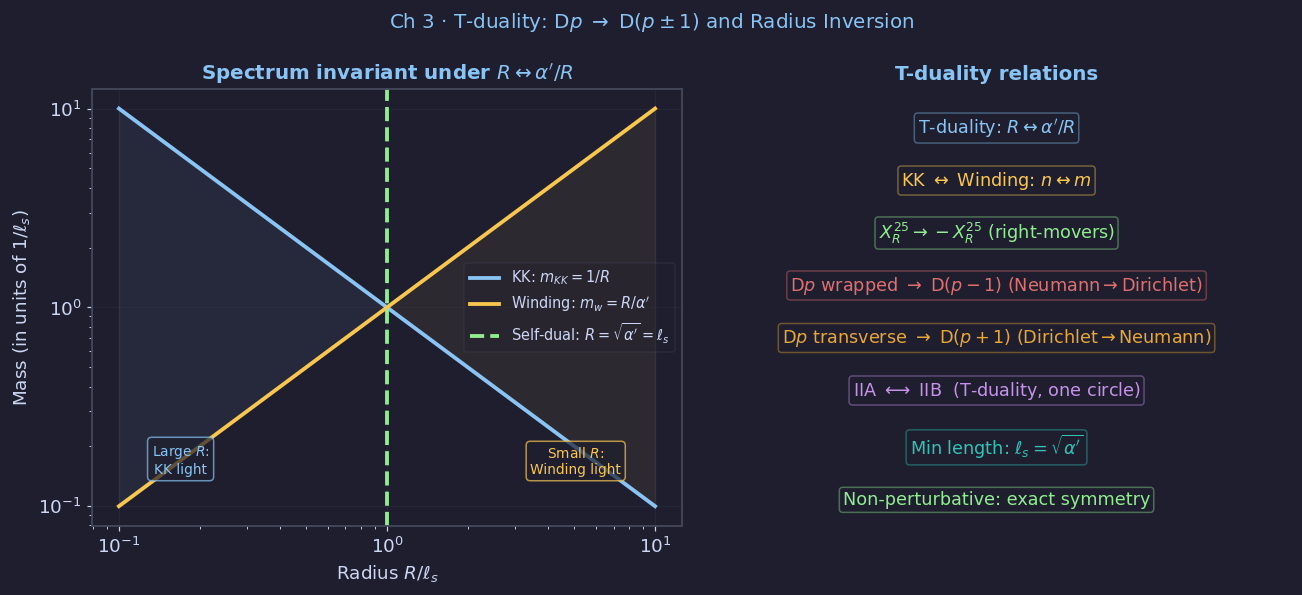

Saved: figures/ch03/fig03_tduality_dbranes.png


In [4]:

# ── fig03: T-duality — D-brane transformation ────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
fig.suptitle(r'Ch 3 · T-duality: D$p$ $\to$ D$(p\pm 1)$ and Radius Inversion',
             color=SKYB, fontsize=13)

# Left: radius inversion spectrum
ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r'Spectrum invariant under $R\leftrightarrow\alpha^{\prime}/R$', color=SKYB)
R = np.logspace(-1, 1, 300)
alpha_prime = 1.0

# Lightest KK and winding modes
m_KK     = 1.0/R                    # n=1 KK
m_winding= R/alpha_prime             # m=1 winding

ax.loglog(R, m_KK,     color=SKYB, lw=2.5, label=r'KK: $m_{KK}=1/R$')
ax.loglog(R, m_winding,color=YELL, lw=2.5, label=r'Winding: $m_w=R/\alpha^{\prime}$')
ax.axvline(np.sqrt(alpha_prime), color=GREEN, lw=2.5, ls='--',
           label=r'Self-dual: $R=\sqrt{\alpha^{\prime}}=\ell_s$')
ax.fill_between(R, m_KK, m_winding,
                where=(R<np.sqrt(alpha_prime)), color=SKYB, alpha=0.07)
ax.fill_between(R, m_winding, m_KK,
                where=(R>np.sqrt(alpha_prime)), color=YELL, alpha=0.07)
ax.set_xlabel(r'Radius $R/\ell_s$')
ax.set_ylabel(r'Mass (in units of $1/\ell_s$)')
ax.legend(fontsize=9.5); ax.grid(True, alpha=0.2)
ax.text(0.15, 0.12, 'Large $R$:\nKK light', transform=ax.transAxes,
        fontsize=9, color=SKYB, ha='center',
        bbox=dict(boxstyle='round', fc=BG, ec=SKYB, alpha=0.7))
ax.text(0.82, 0.12, 'Small $R$:\nWinding light', transform=ax.transAxes,
        fontsize=9, color=YELL, ha='center',
        bbox=dict(boxstyle='round', fc=BG, ec=YELL, alpha=0.7))

# Right: T-duality map
ax2 = axes[1]; ax2.set_facecolor(BG); ax2.axis('off')
ax2.set_title('T-duality relations', color=SKYB)
items = [
    (0.5, 0.91, r'T-duality: $R\leftrightarrow\alpha^{\prime}/R$', SKYB),
    (0.5, 0.79, r'KK $\leftrightarrow$ Winding: $n\leftrightarrow m$', YELL),
    (0.5, 0.67, r'$X^{25}_R\to -X^{25}_R$ (right-movers)', GREEN),
    (0.5, 0.55, r'D$p$ wrapped $\to$ D$(p-1)$ (Neumann$\to$Dirichlet)', RED),
    (0.5, 0.43, r'D$p$ transverse $\to$ D$(p+1)$ (Dirichlet$\to$Neumann)', ORAN),
    (0.5, 0.31, r'IIA $\longleftrightarrow$ IIB  (T-duality, one circle)', PURP),
    (0.5, 0.18, r'Min length: $\ell_s=\sqrt{\alpha^{\prime}}$', TEAL),
    (0.5, 0.06, r'Non-perturbative: exact symmetry', GREEN),
]
for x_,y_,txt,col in items:
    ax2.text(x_,y_,txt,ha='center',va='center',fontsize=11.5,color=col,
             transform=ax2.transAxes,
             bbox=dict(boxstyle='round,pad=0.2',fc=BG,ec=col,alpha=0.4))

plt.tight_layout()
save('fig03_tduality_dbranes.png', fig)


In [5]:
# ── Download all figures as a zip ────────────────────────────────────────
import shutil

shutil.make_archive('ch03_figures', 'zip', 'figures/ch03')

try:
    from google.colab import files
    files.download('ch03_figures.zip')
    print('Download triggered.')
except ImportError:
    print('Not in Colab — figures saved to figures/ch03/')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered.
